In [3]:
# Import libraries
import sqlite3
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")


print("Libraries imported successfully")

Libraries imported successfully


In [19]:
import os


project_root = Path.cwd().parent if Path.cwd().name == 'notebook' else Path.cwd()
src_path = project_root / "src"

print("Does 'src' folder exist?", src_path.exists())
print("Files inside 'src':", os.listdir(src_path) if src_path.exists() else "Folder not found")

Does 'src' folder exist? True
Files inside 'src': ['.ipynb_checkpoints', 'data_preprocessing.py', 'model_evaluation.py', '__init__.py', '__pycache__']


In [21]:


project_root = Path.cwd().parent if Path.cwd().name == 'notebook' else Path.cwd()
src_folder = project_root / 'src'
if str(src_folder) not in sys.path:
    sys.path.insert(0, str(src_folder))


from data_preprocessing import DataPreprocessor

print("DataPreprocessor imported successfully!")

DataPreprocessor imported successfully!


In [23]:
preprocessor = DataPreprocessor()

project_root = Path.cwd().parent if Path.cwd().name == 'notebook' else Path.cwd()
DB_PATH = str(project_root / 'data' / 'inventory.db')

df = preprocessor.load_data(DB_PATH)



Loading data from C:\Users\SAFA MANSOOR\Desktop\project\Invoice-Intelligence-System\data\inventory.db...
✅ Data Loaded: 5543 rows, 10 columns


In [25]:
X_train, X_test, y_train, y_test = preprocessor.split_data(df, cutoff="2024-11-01")

Invalid records removed: 0
Training records: 4497
Testing records: 1046
Cutoff date: 2024-11-01


In [31]:
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(max_depth=4, random_state=42),
    'Random Forest': RandomForestRegressor(max_depth=4, random_state=42)
}
models

{'Linear Regression': LinearRegression(),
 'Decision Tree': DecisionTreeRegressor(max_depth=4, random_state=42),
 'Random Forest': RandomForestRegressor(max_depth=4, random_state=42)}

In [33]:
# train all models
results = {}

print("\nTRAINING STARTED!!!!")

for name, model in models.items():
    print(f"\nTraining started for {name}...")
    # train
    model.fit(X_train, y_train)
    
    # predict
    y_pred = model.predict(X_test)
    
    # calculate Regression Metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = mean_squared_error(y_test, y_pred, squared=False)  # Or numpy sqrt of MSE
    r2 = r2_score(y_test, y_pred)
    
    # store the result
    results[name] = {
        'model': model,
        'mae': mae,
        'rmse': rmse,
        'r2': r2,
        'y_pred': y_pred
    }
    
    print(f"{name} trained")
    print(f"MAE : {mae:.4f}")
    print(f"R² Score : {r2:.4f}")

print("\nTRAINING COMPLETED!!!!")


TRAINING STARTED!!!!

Training started for Linear Regression...
Linear Regression trained
MAE : 21.1657
R² Score : 0.9958

Training started for Decision Tree...
Decision Tree trained
MAE : 39.7645
R² Score : 0.9861

Training started for Random Forest...
Random Forest trained
MAE : 33.4166
R² Score : 0.9814

TRAINING COMPLETED!!!!


In [35]:
for name, res in results.items():
    model = res['model']
    train_score = model.score(X_train, y_train)
    test_score = res['r2']
    print(f"{name} -> Train R²: {train_score:.4f} | Test R²: {test_score:.4f}")

Linear Regression -> Train R²: 0.9610 | Test R²: 0.9958
Decision Tree -> Train R²: 0.9617 | Test R²: 0.9861
Random Forest -> Train R²: 0.9728 | Test R²: 0.9814


,Model,Train R²,Test R²,MAE,RMSE
0,Linear Regression,0.960991,0.995782,21.165706,55.631699
1,Decision Tree,0.961662,0.986124,39.764541,100.907015
2,Random Forest,0.972827,0.981397,33.416554,116.834786


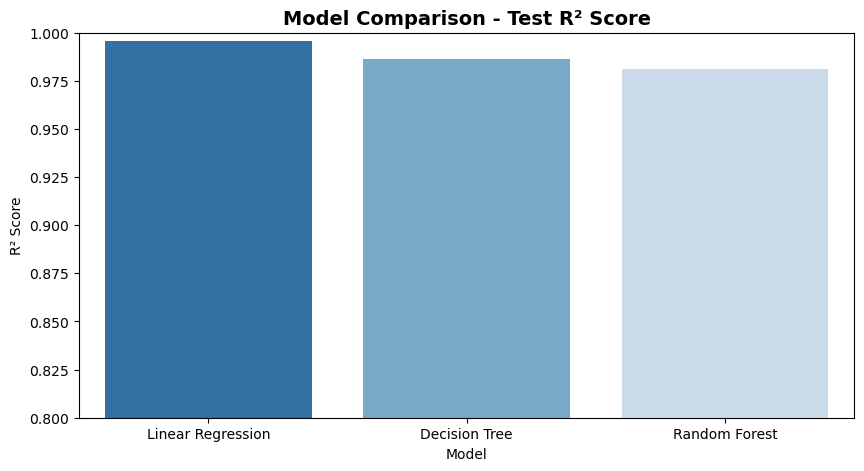

In [39]:
import seaborn as sns
comparison_data = []
for name, res in results.items():
    comparison_data.append({
        'Model': name,
        'Train R²': res['model'].score(X_train, y_train),
        'Test R²': res['r2'],
        'MAE': res['mae'],
        'RMSE': res['rmse']
    })

df_results = pd.DataFrame(comparison_data).sort_values(by='Test R²', ascending=False)
display(df_results)

# 2. Plot comparison bar chart
plt.figure(figsize=(10, 5))
sns.barplot(x='Model', y='Test R²', data=df_results, palette='Blues_r')
plt.title('Model Comparison - Test R² Score', fontsize=14, fontweight='bold')
plt.ylim(0.8, 1.0)  # Adjust based on your score range
plt.ylabel('R² Score')
plt.xlabel('Model')
plt.show()

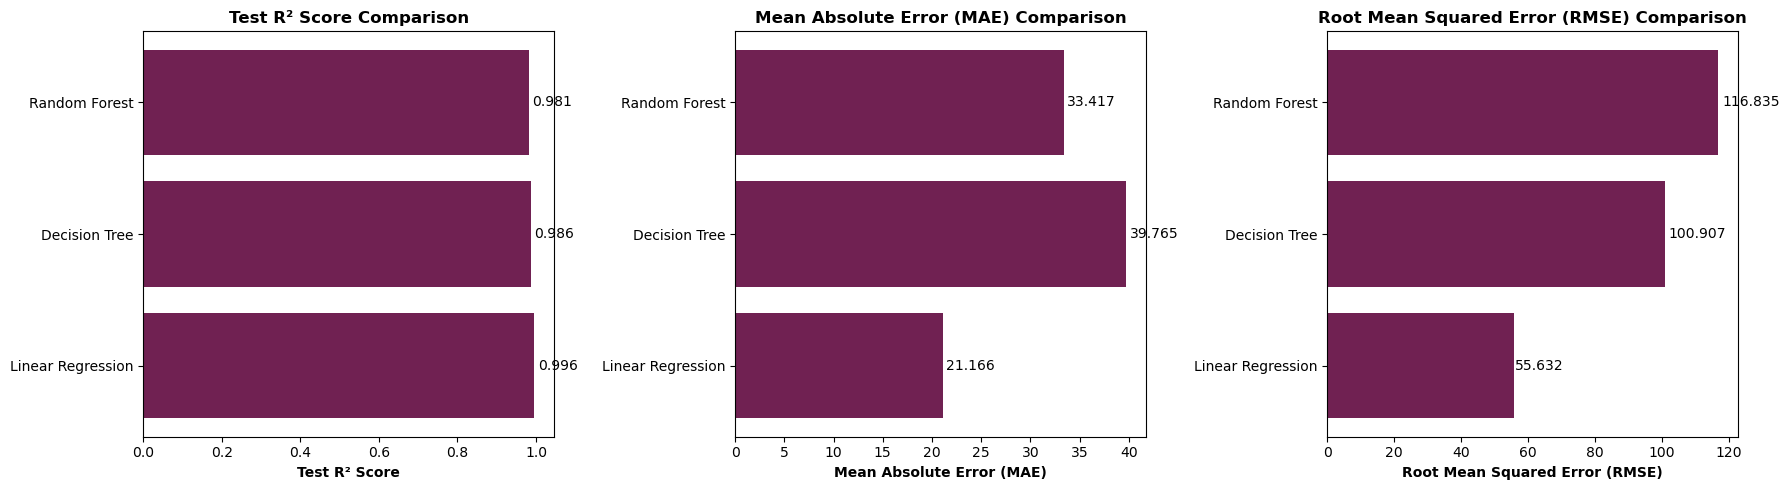

Saved: Model comparison graph in reports


In [41]:
# 2. Plot multi-panel metric comparison charts
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes = axes.flatten()

metrics = ['Test R²', 'MAE', 'RMSE']
metrics_names = ['Test R² Score', 'Mean Absolute Error (MAE)', 'Root Mean Squared Error (RMSE)']

for idx, (metric, metric_name) in enumerate(zip(metrics, metrics_names)):
    
    values = df_results[metric].values
    model_names = df_results['Model'].values
    
    axes[idx].barh(model_names, values, color="#702152")
    axes[idx].set_xlabel(metric_name, fontweight='bold')
    axes[idx].set_title(f'{metric_name} Comparison', fontweight='bold')
    
    
    for i, v in enumerate(values):
        axes[idx].text(v + (v * 0.01), i, f'{v:.3f}', va='center')

plt.tight_layout()
# plt.savefig('../reports/model_comparison_graph.png', dpi=300, bbox_inches='tight')
plt.show()

In [43]:
# Automatically pick the top model from your comparison table
best_model_name = df_results.iloc[0]['Model']
best_model_result = results[best_model_name]

print(f"🏆 Best Model Selected: {best_model_name}")
print(f"Test R² Score: {best_model_result['r2']:.4f}")
print(f"MAE: {best_model_result['mae']:.4f}")

🏆 Best Model Selected: Linear Regression
Test R² Score: 0.9958
MAE: 21.1657


In [45]:
import joblib

best_model = best_model_result['model']
model_path = '../models/predict_freight_model.pkl'

joblib.dump(best_model, model_path)
joblib.dump(preprocessor, '../models/preprocessor.pkl')

print("\nModel Saved Successfully")
print(f"Model Path : {model_path}")


Model Saved Successfully
Model Path : ../models/predict_freight_model.pkl
